In [ ]:
import os
import pandas as pd

file_path = '/content/SupplyChainCleaned.csv'


if os.path.exists(file_path):
    print(f"The file '{file_path}' exists.")
else:
    print(f"The file '{file_path}' does not exist.")

The file '/content/SupplyChainCleaned.csv' exists.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
print("Loading SupplyChainCleaned.csv...")
df = pd.read_csv('SupplyChainCleaned.csv')

# Print the size of the dataset
print("Dataset Shape:", df.shape)

Loading SupplyChainCleaned.csv...
Dataset Shape: (180519, 59)


In [ ]:
# Renaming columns for any errors
column_mapping = {
    'Formatted_order date': 'Order_Date',
    'Delivery Status': 'DeliveryStatus',
    'Delay_Days': 'DelayDays',
    'Days for shipping (real)': 'DaysForShippingReal',
    'Days for shipment (scheduled)': 'DaysForShippingScheduled',
    'Loss_Percentage': 'LossPercentage',
    'Order Id': 'Order_Id',
    'shipping date (DateOrders)': 'Shipping_Date',
    'CostImpactof_Delay': 'CostImpactOfDelay',
    'Benefit per order': 'BenefitPerOrder',
    'Order Region': 'OrderRegion',
    'Late_delivery_risk': 'LateDeliveryRisk',
    'Market': 'Market',
    'Order Item Quantity': 'OrderItemQuantity',
    'Order Item Total': 'OrderItemTotal',
    'Order Item Product Price': 'OrderItemProductPrice'
}
df = df.rename(columns=column_mapping)

# Dropping the rows because majorly data is missing
df = df.dropna(subset=['Order_Date', 'DeliveryStatus', 'DelayDays'])

# Fill shipping days with the median
df['DaysForShippingReal'] = df['DaysForShippingReal'].fillna(df['DaysForShippingReal'].median())

# If product loss is missing, assume 0% loss
df['LossPercentage'] = df['LossPercentage'].fillna(0)


# Convert column data types to correct formats
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Shipping_Date'] = pd.to_datetime(df['Shipping_Date'])
df['DelayDays'] = df['DelayDays'].astype(int)

# Extracting time-based fields for trend analysis
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Quarter'] = df['Order_Date'].dt.quarter
df['DayOfWeek'] = df['Order_Date'].dt.dayofweek # 0=Monday, 6=Sunday


print(f"Data cleaning complete. Cleaned shape: {df.shape}")

Data cleaning complete. Cleaned shape: (180519, 63)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 63 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Type                      180519 non-null  object        
 1   DaysForShippingReal       180519 non-null  int64         
 2   DaysForShippingScheduled  180519 non-null  int64         
 3   BenefitPerOrder           180519 non-null  float64       
 4   Sales per customer        180519 non-null  float64       
 5   DeliveryStatus            180519 non-null  object        
 6   LateDeliveryRisk          180519 non-null  int64         
 7   Category Id               180519 non-null  int64         
 8   Category Name             180519 non-null  object        
 9   Customer City             180519 non-null  object        
 10  Customer Country          180519 non-null  object        
 11  Customer Email            180519 non-null  object        
 12  Cu

In [ ]:
df.head()

,Type,DaysForShippingReal,DaysForShippingScheduled,BenefitPerOrder,Sales per customer,DeliveryStatus,LateDeliveryRisk,Category Id,Category Name,Customer City,...,Shipping Mode,DelayDays,Delay_Category,LossPercentage,CostImpactOfDelay,SupplierRiskScore,Year,Month,Quarter,DayOfWeek
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,Standard Class,-1,Early,0,0.000000,2.11,2018,1,1,2
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,Standard Class,1,Late,50,15.567999,13.05,2018,1,1,5
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,Standard Class,0,On-Time,0,0.000000,1.71,2018,1,1,5
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Standard Class,-1,Early,0,0.000000,2.25,2018,1,1,5
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,Standard Class,-2,Early,0,0.000000,2.25,2018,1,1,5


In [ ]:
# 1. Delay Metrics
avg_delay = df['DelayDays'].mean()
median_delay = df['DelayDays'].median()
std_delay = df['DelayDays'].std()
max_delay = df['DelayDays'].max()

on_time_count = len(df[df['DelayDays'] <= 0])
on_time_rate = (on_time_count / len(df)) * 100
late_rate = 100 - on_time_rate

# 2. Financial Metrics
# Ensure column is numeric
df['CostImpactOfDelay'] = pd.to_numeric(df['CostImpactOfDelay'], errors='coerce').fillna(0)
df['OrderItemTotal'] = pd.to_numeric(df['OrderItemTotal'], errors='coerce').fillna(0)

total_loss = df['CostImpactOfDelay'].sum()
total_sales = df['OrderItemTotal'].sum()
loss_pct_of_sales = (total_loss / total_sales) * 100
avg_loss_per_late_order = df[df['DelayDays'] > 0]['CostImpactOfDelay'].mean()
high_risk_orders_count = len(df[df['CostImpactOfDelay'] > 10000])

# 3. Print the Summary Report
print("============================================================")
print("             SUPPLY CHAIN DISRUPTION METRICS                ")
print("============================================================")
print(f"Total Unique Orders Analyzed: {len(df):,}")
print(f"Date Range: {df['Order_Date'].min().date()} to {df['Order_Date'].max().date()}")
print(f"Markets Covered: {df['Market'].nunique()} global markets")

print("\n--- LOGISTICS PERFORMANCE ---")
print(f"On-Time Delivery Rate: {on_time_rate:.1f}%")
print(f"Late Delivery Rate: {late_rate:.1f}%  (Industry Benchmark is 15%)")
print(f"Average Delay Days: {avg_delay:.2f} days")
print(f"Worst Delay Experienced: {max_delay} days")
print(f"Delay Variation (Std Dev): {std_delay:.2f} days")

print("\n--- FINANCIAL IMPACT OF DELAYS ---")
print(f"Total Financial Loss (Cost Impact): ${total_loss:,.2f}")
print(f"Total Sales Revenue: ${total_sales:,.2f}")
print(f"Percentage of Sales Revenue Lost: {loss_pct_of_sales:.2f}%")
print(f"Average Financial Loss per Late Order: ${avg_loss_per_late_order:.2f}")
print(f"High-Loss Orders (> $10k loss): {high_risk_orders_count:,}")
print("============================================================")

             SUPPLY CHAIN DISRUPTION METRICS                
Total Unique Orders Analyzed: 180,519
Date Range: 2015-01-01 to 2018-01-31
Markets Covered: 5 global markets

--- LOGISTICS PERFORMANCE ---
On-Time Delivery Rate: 42.7%
Late Delivery Rate: 57.3%  (Industry Benchmark is 15%)
Average Delay Days: 0.57 days
Worst Delay Experienced: 4 days
Delay Variation (Std Dev): 1.49 days

--- FINANCIAL IMPACT OF DELAYS ---
Total Financial Loss (Cost Impact): $1,201,420.05
Total Sales Revenue: $33,054,402.38
Percentage of Sales Revenue Lost: 3.63%
Average Financial Loss per Late Order: $11.62
High-Loss Orders (> $10k loss): 0


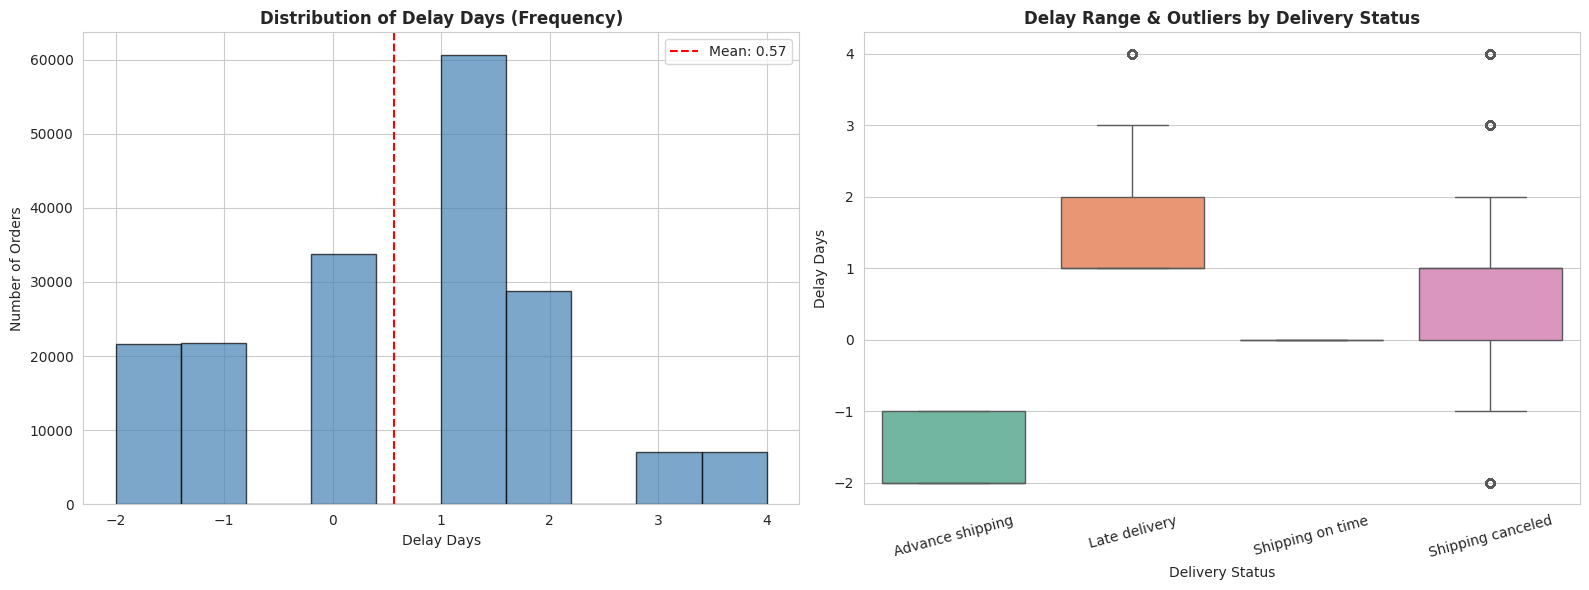

In [ ]:
# Set up a clean 1x2 layout (2 charts side-by-side)
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
-0
# 1.1 Histogram of Delay Days
axes[0].hist(df['DelayDays'], bins=10, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Delay Days (Frequency)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Delay Days')
axes[0].set_ylabel('Number of Orders')
axes[0].axvline(df['DelayDays'].mean(), color='red', linestyle='--', label=f'Mean: {df["DelayDays"].mean():.2f}')
axes[0].legend()

# 1.2 Box Plot of Delay Days by Delivery Status
sns.boxplot(data=df, x='DeliveryStatus', y='DelayDays', ax=axes[1], palette='Set2')
axes[1].set_title('Delay Range & Outliers by Delivery Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Delivery Status')
axes[1].set_ylabel('Delay Days')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('01A_Delay_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

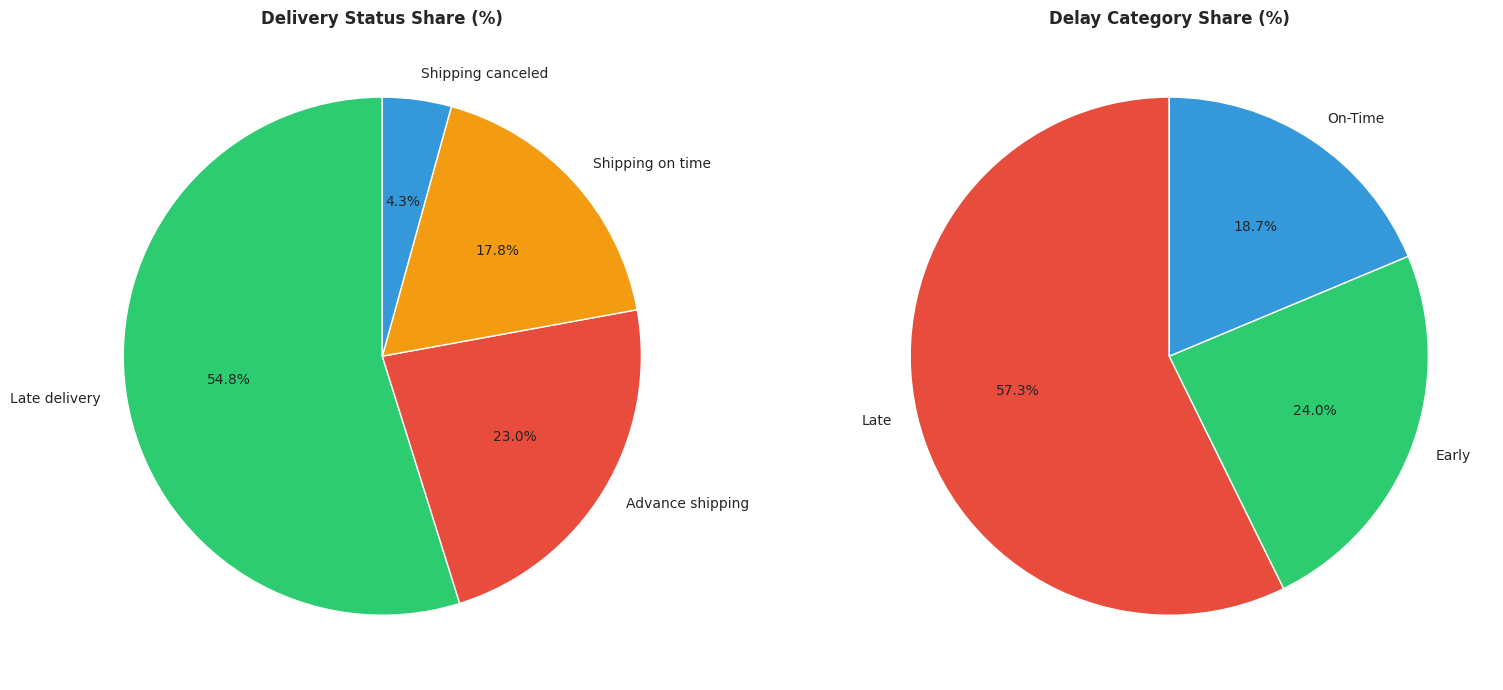

In [ ]:
# Set up a clean 1x2 layout for the pie charts
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1.3 Pie Chart of Delivery Status Breakdown
delivery_counts = df['DeliveryStatus'].value_counts()
colors_delivery = ['#2ecc71', '#e74c3c', '#f39c12', '#3498db']
axes[0].pie(delivery_counts.values, labels=delivery_counts.index, autopct='%1.1f%%',
            colors=colors_delivery, startangle=90, wedgeprops={'edgecolor': 'white'})
axes[0].set_title('Delivery Status Share (%)', fontsize=12, fontweight='bold')

# 1.4 Pie Chart of Delay Category Breakdown
if 'DelayCategory' not in df.columns:
    df['DelayCategory'] = np.where(df['DelayDays'] > 0, 'Late', np.where(df['DelayDays'] < 0, 'Early', 'On-Time'))

category_counts = df['DelayCategory'].value_counts()
colors_category = ['#e74c3c', '#2ecc71', '#3498db']
axes[1].pie(category_counts.values, labels=category_counts.index, autopct='%1.1f%%',
            colors=colors_category, startangle=90, wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Delay Category Share (%)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('01B_Delivery_Composition.png', dpi=300, bbox_inches='tight')
plt.show()

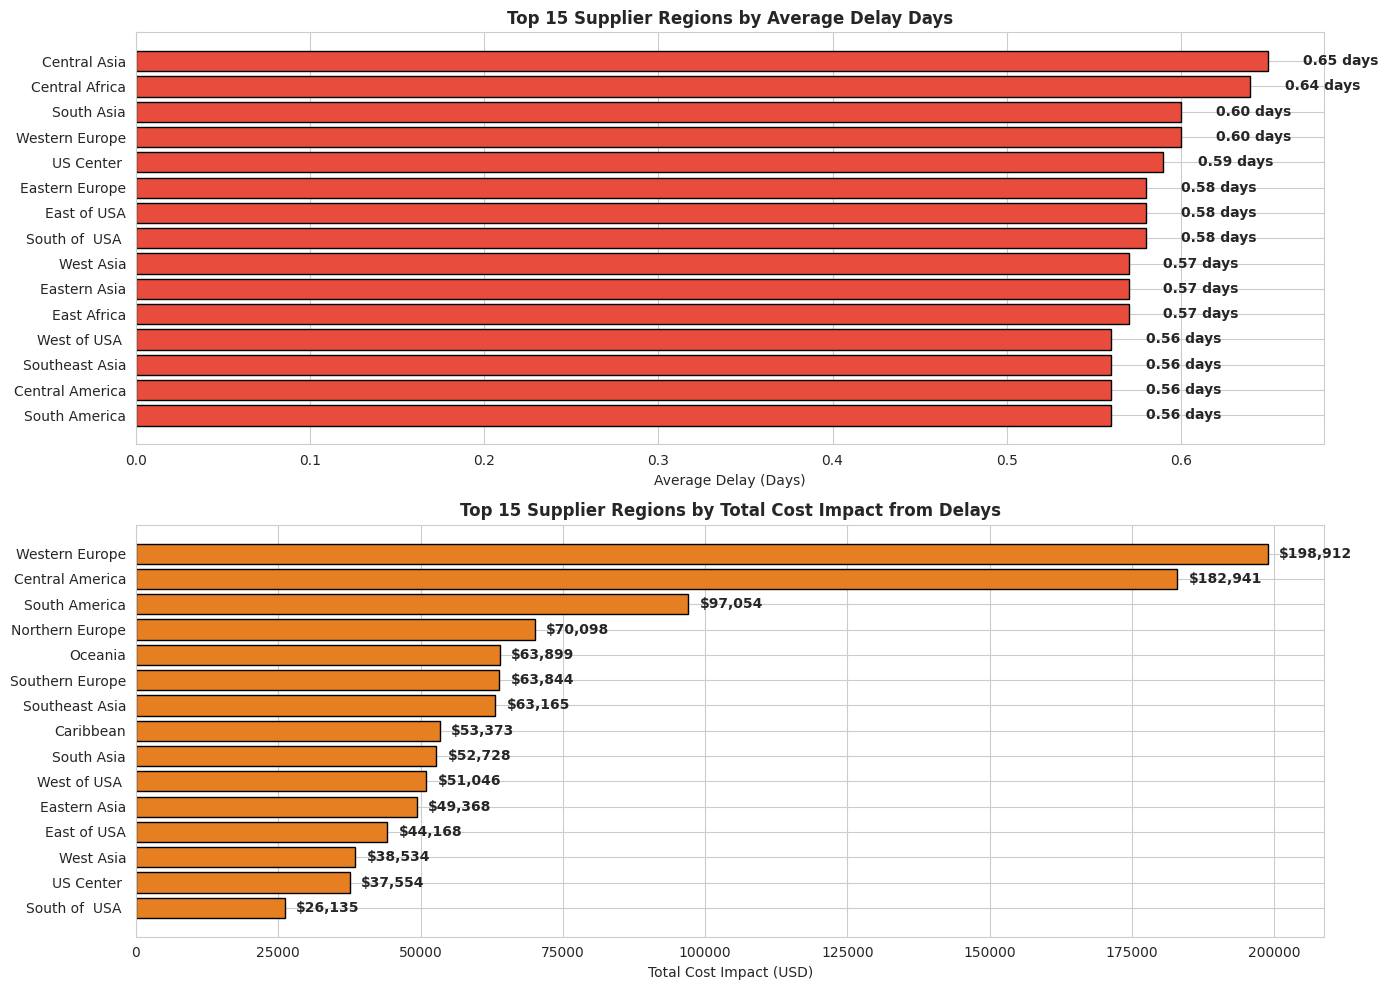

Figure 2 saved successfully as '02_Supplier_Risk_Analysis.png'


In [ ]:
# 1. Group the data by OrderRegion (which represents our suppliers)
# We aggregate the average delay, total orders, average loss, and total financial cost.
supplier_stats = df.groupby('OrderRegion').agg({
    'DelayDays': ['mean', 'count'],
    'LossPercentage': 'mean',
    'CostImpactOfDelay': 'sum'
}).round(2)

# Rename the columns so they are clean and easy to read
supplier_stats.columns = ['AvgDelay', 'OrderCount', 'AvgLoss', 'TotalImpact']

# Filter out regions with very few orders (e.g., less than 50 orders) to avoid statistical noise
supplier_stats = supplier_stats[supplier_stats['OrderCount'] > 50]

# Sort by Average Delay and take the top 15 highest-risk regions
top_delayed_suppliers = supplier_stats.sort_values('AvgDelay', ascending=False).head(15)

# 2. Plotting the results (2 horizontal bar charts in a vertical line)
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Chart 2.1: Top Regions by Average Delay
axes[0].barh(top_delayed_suppliers.index, top_delayed_suppliers['AvgDelay'], color='#e74c3c', edgecolor='black')
axes[0].set_title('Top 15 Supplier Regions by Average Delay Days', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Average Delay (Days)')
axes[0].invert_yaxis()  # Put the highest delay at the top

# Add the actual value labels on the bars
for i, v in enumerate(top_delayed_suppliers['AvgDelay']):
    axes[0].text(v + 0.02, i, f"{v:.2f} days", va='center', fontweight='bold')

# Chart 2.2: Top Regions by Financial Loss (Total Cost Impact)
# Sort by TotalImpact and take the top 15
top_loss_suppliers = supplier_stats.sort_values('TotalImpact', ascending=False).head(15)

axes[1].barh(top_loss_suppliers.index, top_loss_suppliers['TotalImpact'], color='#e67e22', edgecolor='black')
axes[1].set_title('Top 15 Supplier Regions by Total Cost Impact from Delays', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Cost Impact (USD)')
axes[1].invert_yaxis()  # Put the highest cost at the top

# Add the actual money labels on the bars
for i, v in enumerate(top_loss_suppliers['TotalImpact']):
    axes[1].text(v + 2000, i, f"${v:,.0f}", va='center', fontweight='bold')

# Save and display
plt.tight_layout()
plt.savefig('02_Supplier_Risk_Analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 2 saved successfully as '02_Supplier_Risk_Analysis.png'")

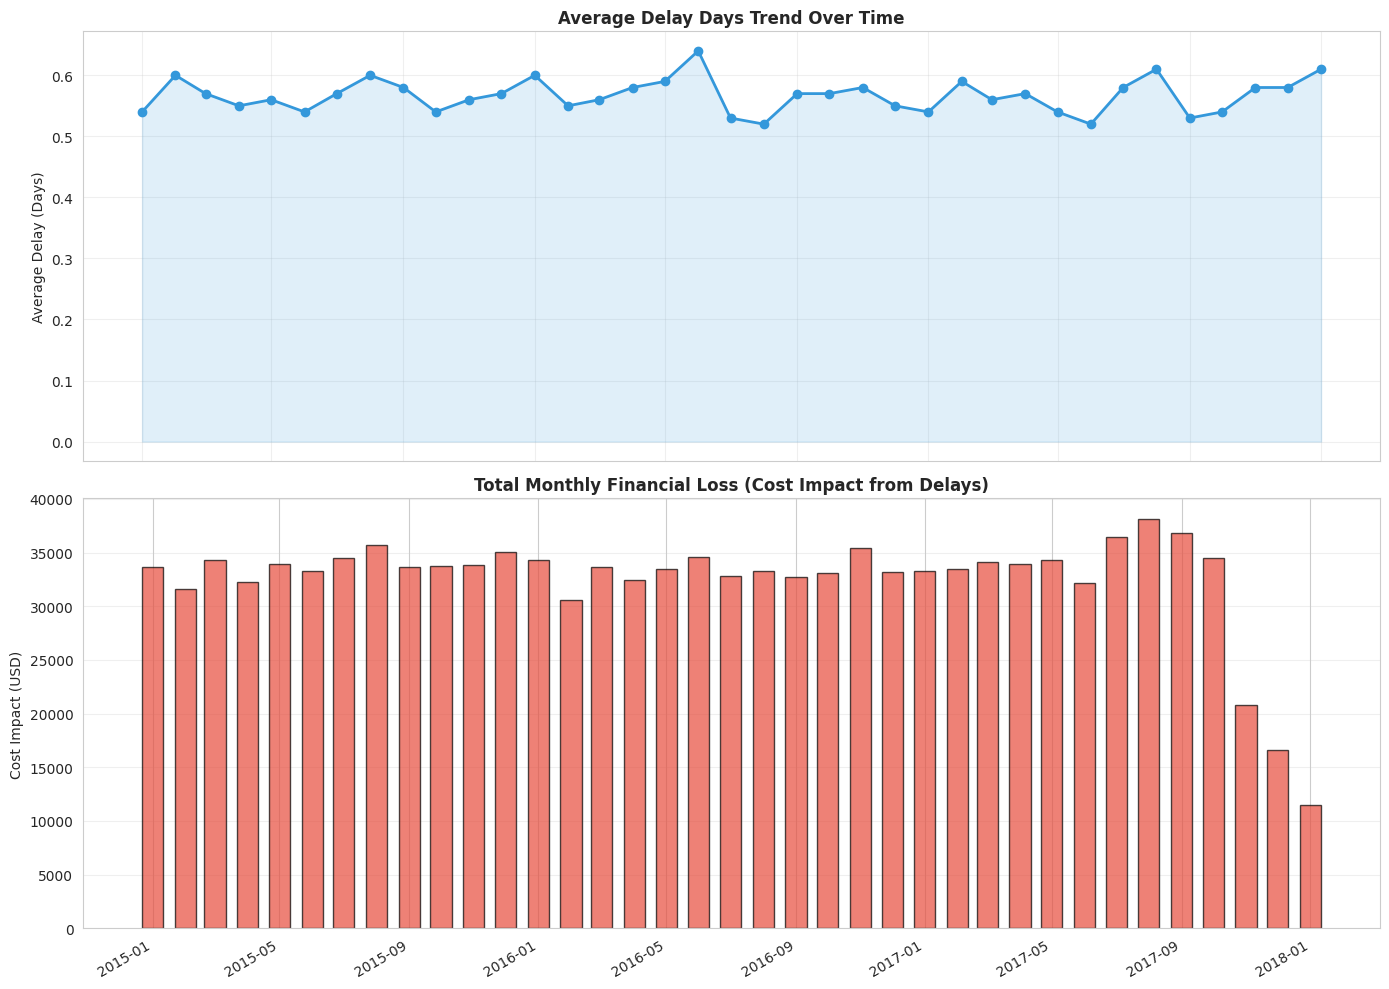

Figure 3 saved successfully as '03_Trend_Analysis.png'


In [ ]:
# 1. Group the data by Year-Month to perform time-series analysis
# .dt.to_period('M') extracts the year and month (e.g. 2017-05)
monthly_stats = df.groupby(df['Order_Date'].dt.to_period('M')).agg({
    'DelayDays': 'mean',
    'Order_Id': 'count',
    'CostImpactOfDelay': 'sum'
}).round(2)

# Convert the monthly index back to standard timestamps so matplotlib can plot them on a timeline
monthly_stats.index = monthly_stats.index.to_timestamp()
monthly_stats.columns = ['AvgDelay', 'OrderCount', 'TotalLoss']

# 2. Plotting (2 charts stacked vertically)
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Chart 3.1: Trend Line of Average Delay over Time
axes[0].plot(monthly_stats.index, monthly_stats['AvgDelay'], marker='o', linewidth=2, color='#3498db')
axes[0].fill_between(monthly_stats.index, monthly_stats['AvgDelay'], alpha=0.15, color='#3498db')
axes[0].set_title('Average Delay Days Trend Over Time', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Average Delay (Days)')
axes[0].grid(True, alpha=0.3)

# Chart 3.2: Bar Chart of Monthly Cost Impact
axes[1].bar(monthly_stats.index, monthly_stats['TotalLoss'], width=20, color='#e74c3c', alpha=0.7, edgecolor='black')
axes[1].set_title('Total Monthly Financial Loss (Cost Impact from Delays)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Cost Impact (USD)')
axes[1].grid(True, axis='y', alpha=0.3)

# Format dates on the X-axis so they read nicely
plt.gcf().autofmt_xdate()

# Save and display
plt.tight_layout()
plt.savefig('03_Trend_Analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 3 saved successfully as '03_Trend_Analysis.png'")

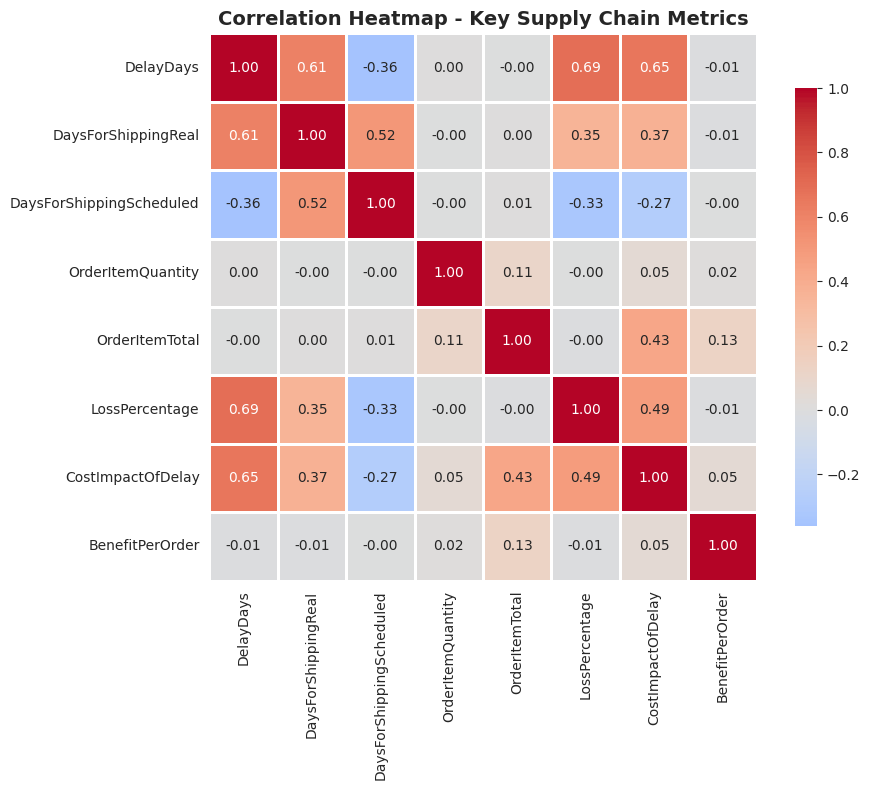

Figure 4 saved successfully as '04_Correlation_Heatmap.png'


In [ ]:
# 1. Define the numeric columns we want to compare
numeric_cols = ['DelayDays', 'DaysForShippingReal', 'DaysForShippingScheduled',
                'OrderItemQuantity', 'OrderItemTotal', 'LossPercentage',
                'CostImpactOfDelay', 'BenefitPerOrder']

# Force columns to be numeric types just in case
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# 2. Calculate the correlation matrix
correlation_matrix = df[numeric_cols].corr()

# 3. Plotting the heatmap
fig, ax = plt.subplots(figsize=(10, 8))

# 'coolwarm' color map makes positive correlations red and negative correlations blue
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title('Correlation Heatmap - Key Supply Chain Metrics', fontsize=14, fontweight='bold')

# Save and display
plt.tight_layout()
plt.savefig('04_Correlation_Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 4 saved successfully as '04_Correlation_Heatmap.png'")

In [ ]:
# 1. Define the Risk Scoring Function
def calculate_supplier_risk_score(group_df):
    """
    Calculates a risk score for a supplier group on a scale of 0 to 100.
    - Component 1: Average Delay (40% weight) - measures severity of delays.
    - Component 2: Late Delivery Frequency (40% weight) - measures reliability.
    - Component 3: Product Loss Rate (20% weight) - measures quality/loss.
    """
    # Component 1: Average Delay (Normalized to a 0-30 day scale, capped at 100)
    avg_delay = group_df['DelayDays'].mean()
    # If the average delay is positive, we scale it. If negative (early), we treat delay score as 0.
    delay_score = min((max(0, avg_delay) / 30) * 100, 100)

    # Component 2: Late Delivery Frequency (Percentage of orders that were late)
    late_count = len(group_df[group_df['DelayDays'] > 0])
    late_frequency = (late_count / len(group_df)) * 100
    late_score = late_frequency

    # Component 3: Product Loss Rate (Average loss percentage, capped at 100)
    loss_score = min(group_df['LossPercentage'].mean(), 100)

    # Calculate the weighted score
    risk_score = (delay_score * 0.4) + (late_score * 0.4) + (loss_score * 0.2)
    return risk_score

# 2. Apply the algorithm to each supplier region
# We group by OrderRegion and apply the custom function to each group
supplier_risk = df.groupby('OrderRegion').apply(calculate_supplier_risk_score, include_groups=False)

# 3. Create a clean DataFrame to display the results and compile metrics
risk_df = pd.DataFrame({
    'Supplier_Region': supplier_risk.index,
    'Risk_Score': supplier_risk.values
})

# 4. Add additional business metrics for each region to help explain the risk scores
for supplier in risk_df['Supplier_Region']:
    supplier_data = df[df['OrderRegion'] == supplier]

    # Calculate and assign stats
    risk_df.loc[risk_df['Supplier_Region'] == supplier, 'Avg_Delay_Days'] = supplier_data['DelayDays'].mean()
    risk_df.loc[risk_df['Supplier_Region'] == supplier, 'Late_Delivery_Percent'] = (len(supplier_data[supplier_data['DelayDays'] > 0]) / len(supplier_data)) * 100
    risk_df.loc[risk_df['Supplier_Region'] == supplier, 'Order_Count'] = len(supplier_data)
    risk_df.loc[risk_df['Supplier_Region'] == supplier, 'Total_Cost_Impact'] = supplier_data['CostImpactOfDelay'].sum()

# Sort the table from highest risk (riskiest regions) to lowest risk
risk_df = risk_df.sort_values('Risk_Score', ascending=False).round(2)

# Display the final table
print("==========================================================================")
print("                    SUPPLIER RISK SCORES (0-100 SCALE)                    ")
print("==========================================================================")
print(risk_df.to_string(index=False))
print("==========================================================================")

# 5. Export to CSV (This CSV will be imported directly into Power BI!)
risk_df.to_csv('Supplier_Risk_Analysis.csv', index=False)
print("\n✓ Exported: Supplier_Risk_Analysis.csv")

                    SUPPLIER RISK SCORES (0-100 SCALE)                    
Supplier_Region  Risk_Score  Avg_Delay_Days  Late_Delivery_Percent  Order_Count  Total_Cost_Impact
 Central Africa       31.66            0.64                  60.70       1677.0           11156.50
 Western Europe       30.70            0.60                  58.52      27109.0          198912.37
     South Asia       30.54            0.60                  58.50       7731.0           52728.08
 South of  USA        30.53            0.58                  58.10       4045.0           26135.04
    East of USA       30.40            0.58                  57.98       6915.0           44168.06
 Southeast Asia       30.34            0.56                  57.98       9539.0           63164.88
      West Asia       30.16            0.57                  57.50       6009.0           38533.53
    East Africa       30.10            0.57                  57.45       1852.0           12180.53
  South America       30.07       

In [ ]:
# 1. Group by Market and calculate aggregate metrics
market_analysis = df.groupby('Market').agg({
    'Order_Id': 'count',
    'DelayDays': 'mean',
    'LateDeliveryRisk': 'mean',  # The average of a 0/1 binary field is the fraction. We'll multiply by 100.
    'CostImpactOfDelay': 'sum',
    'OrderItemTotal': 'sum'
}).round(2)

# Rename the columns for clarity
market_analysis.columns = ['Order_Count', 'Avg_Delay_Days', 'Late_Risk_Percent', 'Total_Loss', 'Total_Sales']

# Convert Late_Risk_Percent to a 0-100 scale percentage
market_analysis['Late_Risk_Percent'] = (market_analysis['Late_Risk_Percent'] * 100).round(2)

# Calculate Loss as a Percentage of Sales
# This shows how much revenue is lost to delays relative to the market's size
market_analysis['Loss_as_Percent_of_Sales'] = ((market_analysis['Total_Loss'] / market_analysis['Total_Sales']) * 100).round(2)

# Sort by Average Delay Days (worst markets at the top)
market_analysis = market_analysis.sort_values('Avg_Delay_Days', ascending=False)

# Display the table
print("==========================================================================================")
print("                             MARKET-WISE PERFORMANCE                                      ")
print("==========================================================================================")
print(market_analysis)
print("==========================================================================================")

# 2. Export to CSV (This CSV will also go straight into Power BI!)
market_analysis.to_csv('Market_Analysis.csv')
print("\n✓ Exported: Market_Analysis.csv")

                             MARKET-WISE PERFORMANCE                                      
              Order_Count  Avg_Delay_Days  Late_Risk_Percent  Total_Loss  \
Market                                                                     
Europe              50252            0.57               55.0   358308.66   
USCA                25799            0.57               55.0   164631.18   
Pacific Asia        41260            0.57               55.0   271511.08   
Africa              11614            0.56               55.0    73600.85   
LATAM               51594            0.56               54.0   333368.29   

              Total_Sales  Loss_as_Percent_of_Sales  
Market                                               
Europe         9769198.32                      3.67  
USCA           4553499.92                      3.62  
Pacific Asia   7434262.65                      3.65  
Africa         2061679.39                      3.57  
LATAM          9235762.09                      3.61 

In [ ]:
# ==================== STEP 10: FINAL SUMMARY REPORT ====================
# We compile all findings into a structured, professional report and export it.


summary_report = f"""
================================================================================
                    SUPPLY CHAIN DISRUPTION ANALYSIS - REPORT
================================================================================

1. DATASET OVERVIEW
--------------------------------------------------------------------------------
* Total Unique Orders Analyzed : {len(df):,}
* Date Range                   : {df['Order_Date'].min().date()} to {df['Order_Date'].max().date()}
* Markets Covered              : {df['Market'].nunique()} global markets

2. LOGISTICS PERFORMANCE
--------------------------------------------------------------------------------
* On-Time Delivery Rate        : {on_time_rate:.1f}%
* Late Delivery Rate           : {late_rate:.1f}%  (Industry Benchmark: 15%)
* Average Delay                : {avg_delay:.2f} days
* Worst Delay Recorded         : {max_delay} days

3. FINANCIAL IMPACT OF DELAYS
--------------------------------------------------------------------------------
* Total Cost Impact (Losses)   : ${total_loss:,.2f}
* Percentage of Sales Lost     : {loss_pct_of_sales:.2f}%
* Average Loss per Late Order  : ${avg_loss_per_late_order:.2f}
* High-Loss Orders (> $10k)    : {high_risk_orders_count:,}

4. TOP 5 HIGH-RISK SUPPLIER REGIONS (Based on our Risk Scoring Model)
--------------------------------------------------------------------------------
{risk_df.head(5)[['Supplier_Region', 'Risk_Score', 'Avg_Delay_Days']].to_string(index=False)}

5. ACTIONABLE RECOMMENDATIONS FOR THE BUSINESS
--------------------------------------------------------------------------------
1. PRIORITIZE HIGH-RISK REGIONS: Focus immediate operational reviews on the
   top risk region: {risk_df.iloc[0]['Supplier_Region']} (Risk Score: {risk_df.iloc[0]['Risk_Score']:.1f}/100).
2. RENEGOTIATE SERVICE LEVEL AGREEMENTS (SLAs): Implement financial penalties
   for couriers with an average delay of more than 0.5 days.
3. BUFFER INVENTORY: Increase safety stock levels by 20% in high-risk regions
   to shield customers from fulfillment delays.
4. TARGET HIGH-VALUE LOSSES: Establish special routing and tracking protocols
   for high-value shipments (orders > $10,000) to minimize the cost impact of delays.

================================================================================
"""

# Print the report directly in Colab
print(summary_report)

# Save the report to a text file in Colab
with open('Supply_Chain_Analysis_Report.txt', 'w') as f:
    f.write(summary_report)

print("✓ Exported report to 'Supply_Chain_Analysis_Report.txt'")


                    SUPPLY CHAIN DISRUPTION ANALYSIS - REPORT

1. DATASET OVERVIEW
--------------------------------------------------------------------------------
* Total Unique Orders Analyzed : 180,519
* Date Range                   : 2015-01-01 to 2018-01-31
* Markets Covered              : 5 global markets

2. LOGISTICS PERFORMANCE
--------------------------------------------------------------------------------
* On-Time Delivery Rate        : 42.7%
* Late Delivery Rate           : 57.3%  (Industry Benchmark: 15%)
* Average Delay                : 0.57 days
* Worst Delay Recorded         : 4 days

3. FINANCIAL IMPACT OF DELAYS
--------------------------------------------------------------------------------
* Total Cost Impact (Losses)   : $1,201,420.05
* Percentage of Sales Lost     : 3.63%
* Average Loss per Late Order  : $11.62
* High-Loss Orders (> $10k)    : 0

4. TOP 5 HIGH-RISK SUPPLIER REGIONS (Based on our Risk Scoring Model)
-----------------------------------------------